# Feature selection and feature engineering: diagnosis

**Scope of this notebook.** Sections 0-5 (diagnosis) answer three questions on the **development set** (the locked test set is never touched); sections 6 and 7 then test, by paired ablation on the same temporal folds, the engineered features (step 2) and the feature-selection step (step 3):

1. **Redundancy** (section 1): which features carry the same information (Spearman clusters, VIF)?
2. **Relevance** (section 2): which features carry information about the target (mutual information)?
3. **Usefulness for the chosen model** (section 3): what happens to the temporal-CV score when a feature is shuffled (out-of-fold permutation importance)?

Section 4 merges the three into one table of **drop candidates**. They are candidates, not decisions: each one is confirmed or rejected afterwards by a paired ablation on the same temporal folds (`compare_preprocessing_variants` + `paired_comparison`), as in notebook 01, section 11.4.

**Reading rules**
- Mutual information and correlations are *descriptive*: they use all development rows at once, so they must not be used to pick features without the ablation.
- Permutation importance is computed **out of fold**: the model is fitted on the training rows of each temporal fold and the column is shuffled in the validation rows of that fold only.
- Features that are not in the current recipe (`margin`, `discount_rate`, ...) are included in sections 1 and 2 so they can be compared with the ones in use; section 3 only covers the features the recipe actually feeds to the model.

In [1]:
import os
import sys
import warnings
from pathlib import Path

# run from the project root, whether Jupyter was started there or in notebooks/
ROOT = Path.cwd() if (Path.cwd() / "config.yaml").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform
from sklearn.feature_selection import mutual_info_classif, mutual_info_regression
from sklearn.inspection import permutation_importance

from src.evaluate import (
    compare_preprocessing_variants, greater_is_better, paired_comparison, select_scoring, temporal_folds,
)
from src.pipeline import build_pipeline, prepare_task_data
from src.tasks import TASKS, get_task

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

with open("config.yaml", encoding="utf-8") as f:
    config = yaml.safe_load(f)
data_cfg = config["data"]

SCORING = {task: select_scoring(TASKS[task].evaluate.SCORING, config[task]["metrics"]) for task in TASKS}
SEED = config["preprocessing"].get("random_state", 42)

## 0. Data and per-task feature groups

`prepare_task_data` runs the same load, validate, clean and split steps as `main.py`, so `X_dev` already holds **every** column the cleaning step produces (including the ones the recipe does not use). Each task keeps its own development set: the regression one only has repeat purchasers.

In [2]:
data, folds = {}, {}
for task in TASKS:
    data[task] = prepare_task_data(config, task)
    dates = data[task]["extras_dev"][data_cfg["date_column"]]
    folds[task] = temporal_folds(dates, config["cv"]["n_splits"], config["cv"]["gap_days"])


def feature_groups(task):
    """Which columns of X_dev are categorical, numeric-like, and which ones the recipe uses."""
    recipe, X = data[task]["preprocessing_config"], data[task]["X_dev"]
    categorical = [c for c in X.columns if str(X[c].dtype) == "category"]
    numeric = [c for c in X.columns if c not in categorical]
    used = (recipe["numeric_features"] + recipe["categorical_features"]
            + list(recipe.get("flag_features", [])))
    return {"categorical": categorical, "numeric": numeric, "used": used, "recipe": recipe}


groups = {task: feature_groups(task) for task in TASKS}
summary = pd.DataFrame({
    task: {"dev rows": len(data[task]["X_dev"]), "temporal folds": len(folds[task]),
           "columns in X_dev": data[task]["X_dev"].shape[1], "columns used by the recipe": len(groups[task]["used"]),
           "numeric-like not used": len([c for c in groups[task]["numeric"] if c not in groups[task]["used"]]),
           "categorical not used": len([c for c in groups[task]["categorical"] if c not in groups[task]["used"]])}
    for task in TASKS})
display(summary)

,classification,regression
dev rows,5024,2659
temporal folds,5,5
columns in X_dev,56,56
columns used by the recipe,34,43
numeric-like not used,18,13
categorical not used,4,0


## 1. Redundancy

### 1.1 Spearman correlation clusters

Spearman (rank) correlation, because most money and count columns are heavily skewed. Features are grouped by average-linkage hierarchical clustering on `1 - |rho|`, cutting at `|rho| >= 0.90` on average. A cluster with more than one member is a group of near-duplicates: at most one (or a ratio of them) should be needed by a linear model.

In [3]:
RHO_CUT = 0.90


def numeric_frame(task):
    X, g = data[task]["X_dev"], groups[task]
    return X[g["numeric"]].astype("float64")


def correlation_clusters(task):
    Xn = numeric_frame(task)
    Xn = Xn.loc[:, Xn.nunique() > 1]                         # constants have no correlation
    rho = Xn.corr(method="spearman").fillna(0.0)
    dist = 1 - rho.abs().to_numpy()
    np.fill_diagonal(dist, 0.0)
    labels = hierarchy.fcluster(hierarchy.linkage(squareform(dist, checks=False), "average"),
                                t=1 - RHO_CUT, criterion="distance")
    return rho, pd.Series(labels, index=rho.index, name="cluster")


rho, cluster = {}, {}
for task in TASKS:
    rho[task], cluster[task] = correlation_clusters(task)
    sizes = cluster[task].map(cluster[task].value_counts())
    rows = []
    for label in sorted(cluster[task][sizes > 1].unique()):
        members = cluster[task][cluster[task] == label].index.tolist()
        sub = rho[task].loc[members, members].abs().to_numpy()
        rows.append({"cluster": label, "size": len(members),
                     "min |rho|": sub[np.triu_indices(len(members), 1)].min().round(3),
                     "in recipe": [m for m in members if m in groups[task]["used"]],
                     "not in recipe": [m for m in members if m not in groups[task]["used"]]})
    print(f"\n{task.upper()}: {len(rows)} clusters with more than one feature (|rho| >= {RHO_CUT})")
    display(pd.DataFrame(rows).set_index("cluster"))


CLASSIFICATION: 8 clusters with more than one feature (|rho| >= 0.9)


,size,min |rho|,in recipe,not in recipe
cluster,,,,
3,2,0.942,[net_total],[margin]
10,2,0.921,"[prior_std_purchase_value, prior_max_purchase_...",[]
12,2,0.907,"[prior_purchase_count, prior_total_spend]",[]
13,2,0.904,"[spend_180d, spend_365d]",[]
25,3,0.945,"[purchase_count_30d, spend_30d]",[spend_share_30d]
26,2,0.956,[],"[spend_share_90d, count_share_90d]"
27,2,0.921,"[purchase_count_90d, spend_90d]",[]
29,2,0.902,[line_discount_total],[discount_rate]



REGRESSION: 5 clusters with more than one feature (|rho| >= 0.9)


,size,min |rho|,in recipe,not in recipe
cluster,,,,
6,2,0.939,[net_total],[margin]
12,2,0.905,[],"[spend_share_90d, count_share_90d]"
15,3,0.893,"[purchase_count_30d, spend_30d]",[spend_share_30d]
19,2,0.916,"[prior_std_purchase_value, prior_max_purchase_...",[]
24,2,0.902,"[spend_180d, spend_365d]",[]


### 1.2 Strongest pairs

The clusters above can chain features together; the pairs below show the actual strength of each link.

In [4]:
def top_pairs(task, n=15):
    r = rho[task].abs()
    upper = r.where(np.triu(np.ones(r.shape, dtype=bool), 1)).stack()
    pairs = upper.sort_values(ascending=False).head(n).rename("|rho|").reset_index()
    pairs.columns = ["feature A", "feature B", "|rho|"]
    pairs["both in recipe"] = [a in groups[task]["used"] and b in groups[task]["used"]
                               for a, b in zip(pairs["feature A"], pairs["feature B"])]
    return pairs.round(3)


for task in TASKS:
    print(f"\n{task.upper()}")
    display(top_pairs(task))


CLASSIFICATION


,feature A,feature B,|rho|,both in recipe
0,purchase_count_30d,spend_30d,0.965,True
1,spend_30d,spend_share_30d,0.965,False
2,spend_share_90d,count_share_90d,0.956,False
3,purchase_count_30d,spend_share_30d,0.945,False
4,net_total,margin,0.942,False
5,prior_std_purchase_value,prior_max_purchase_value,0.921,True
6,purchase_count_90d,spend_90d,0.921,True
7,prior_purchase_count,prior_total_spend,0.907,True
8,spend_180d,spend_365d,0.904,True
9,line_discount_total,discount_rate,0.902,False



REGRESSION


,feature A,feature B,|rho|,both in recipe
0,spend_30d,spend_share_30d,0.947,False
1,net_total,margin,0.939,False
2,net_total,total_tax,0.928,True
3,purchase_count_30d,spend_30d,0.925,True
4,prior_std_purchase_value,prior_max_purchase_value,0.916,True
5,spend_share_90d,count_share_90d,0.905,False
6,spend_180d,spend_365d,0.902,True
7,purchase_count_180d,purchase_count_365d,0.898,True
8,purchase_count_30d,spend_share_30d,0.893,False
9,customer_tenure_days,years_as_customer,0.889,True


### 1.3 Variance inflation factor (features in the recipe)

VIF of feature *j* is `1 / (1 - R²_j)`, with R²_j from regressing it on all the others. It is the number that matters for **logistic regression and Ridge** (classification's current model): a VIF above 10 means the coefficient is poorly determined, even if prediction is fine. Trees and forests are not affected by collinearity in the same way. Median imputation and standardisation first, same as the recipe; the VIF comes from the diagonal of the inverse correlation matrix.

In [5]:
def vif_table(task):
    Xn = numeric_frame(task)
    cols = [c for c in groups[task]["recipe"]["numeric_features"] + list(groups[task]["recipe"].get("flag_features", []))
            if c in Xn.columns]
    Z = Xn[cols]
    Z = Z.fillna(Z.median())
    Z = Z.loc[:, Z.std() > 0]
    Z = (Z - Z.mean()) / Z.std()
    inv = np.linalg.pinv(np.corrcoef(Z.to_numpy(), rowvar=False))
    return pd.Series(np.diag(inv), index=Z.columns, name="VIF").sort_values(ascending=False)


vif = {task: vif_table(task) for task in TASKS}
for task in TASKS:
    print(f"\n{task.upper()}: {int((vif[task] > 10).sum())} of {len(vif[task])} features have VIF > 10, "
          f"{int((vif[task] > 5).sum())} have VIF > 5 (top 12 below)")
    display(vif[task].head(12).round(1).to_frame())


CLASSIFICATION: 7 of 28 features have VIF > 10, 15 have VIF > 5 (top 12 below)


,VIF
purchase_count_180d,29.2
purchase_count_365d,22.5
prior_std_purchase_value,19.8
prior_mean_purchase_value,19.5
purchase_count_90d,16.6
prior_max_purchase_value,12.2
spend_180d,10.7
spend_365d,8.9
prior_purchase_count,8.6
prior_total_spend,8.3



REGRESSION: 7 of 33 features have VIF > 10, 16 have VIF > 5 (top 12 below)


,VIF
purchase_count_180d,29.6
purchase_count_365d,21.8
prior_std_purchase_value,18.5
prior_mean_purchase_value,17.8
purchase_count_90d,16.5
prior_max_purchase_value,10.7
spend_180d,10.2
net_total,8.6
spend_365d,8.5
prior_purchase_count,8.3


## 2. Relevance: mutual information with the target

Mutual information captures non-linear dependence too. Numeric columns (median-imputed) use the k-nearest-neighbour estimator; categorical columns and 0/1 flags are treated as discrete variables (integer codes). Each column is estimated on its own so the numbers do not change when a column is added to the data. Estimates are noisy on small samples (regression has fewer than 3,000 rows), so treat the ranking as a guide, and look at the gap to the `random_noise`-like level rather than at the exact order. To get that reference level, a **shuffled copy of the target** is scored too: any feature whose MI is not clearly above it carries no usable signal.

In [6]:
def mutual_information(task, seed=SEED):
    """MI of every column with the target, and with a shuffled copy of the target (noise floor).
    One column at a time: the kNN estimator adds random noise, and with all columns in one call
    that noise (hence every estimate) would change whenever a column is added to X_dev.
    Categorical columns and 0/1 flags are discrete variables, the rest continuous."""
    X, y = data[task]["X_dev"], data[task]["y_dev"]
    g = groups[task]
    num = X[g["numeric"]].astype("float64")
    num = num.fillna(num.median())
    cat = X[g["categorical"]].apply(lambda s: s.cat.codes if str(s.dtype) == "category" else s)
    frame = pd.concat([num, cat], axis=1)
    discrete = {c: (c in g["categorical"]) or frame[c].nunique() <= 2 for c in frame.columns}
    mi_function = mutual_info_classif if task == "classification" else mutual_info_regression
    target = y.to_numpy()
    shuffled = np.random.default_rng(seed).permutation(target)
    estimate = lambda c, t: mi_function(frame[[c]], t, discrete_features=[discrete[c]], random_state=seed)[0]
    mi = pd.Series({c: estimate(c, target) for c in frame.columns})
    floor = pd.Series({c: estimate(c, shuffled) for c in frame.columns})
    return mi, floor


mi, mi_floor = {}, {}
for task in TASKS:
    mi[task], mi_floor[task] = mutual_information(task)
    print(f"{task}: MI of the shuffled target, max over features = {mi_floor[task].max():.4f}, "
          f"median = {mi_floor[task].median():.4f}")
for task in TASKS:
    print(f"\n{task.upper()}: top 12 features by mutual information")
    display(pd.DataFrame({"MI": mi[task], "in recipe": [c in groups[task]["used"] for c in mi[task].index]})
            .sort_values("MI", ascending=False).head(12).round(4))

classification: MI of the shuffled target, max over features = 0.0178, median = 0.0009
regression: MI of the shuffled target, max over features = 0.0389, median = 0.0009

CLASSIFICATION: top 12 features by mutual information


,MI,in recipe
prior_max_purchase_value,0.1525,True
prior_min_purchase_value,0.1454,True
purchase_count_365d,0.1208,True
purchase_rate,0.1140,False
prior_mean_gap_days,0.1071,True
purchase_count_180d,0.1030,True
purchase_count_90d,0.1009,True
count_share_90d,0.0960,False
spend_365d,0.0930,True
spend_180d,0.0846,True



REGRESSION: top 12 features by mutual information


,MI,in recipe
spend_365d,0.2980,True
prior_max_purchase_value,0.2951,True
purchase_rate,0.2602,False
prior_purchase_count,0.2466,True
municipality,0.2424,True
spend_180d,0.2379,True
prior_total_spend,0.2333,True
purchase_count_180d,0.2219,True
purchase_count_365d,0.2215,True
prior_std_purchase_value,0.2135,True


## 3. Usefulness for the chosen model: out-of-fold permutation importance

For each temporal fold: fit the task's **current** pipeline (recipe + model from `config.yaml`) on the training rows, then shuffle one column at a time in the validation rows and measure how much the selection metric gets worse (5 repeats). The importance is expressed in the metric's own units (accuracy points for classification, RMSE in euros for regression), so a positive number means "the model needs this column". Shuffling is done on the **raw input columns**, so the encoder and the scaler are re-applied to the shuffled values, exactly as they would be on real data.

Only columns the recipe feeds to the model are shuffled: shuffling an unused column cannot change anything. The `spend_365d` missing indicator is created inside the pipeline from `spend_365d`, so its effect is part of that column's importance.

In [7]:
N_REPEATS = 5


def oof_permutation_importance(task):
    X, y = data[task]["X_dev"], data[task]["y_dev"]
    metric = config[task]["selection_metric"]
    scorer = SCORING[task][metric]
    recipe = groups[task]["recipe"]
    columns = [c for c in groups[task]["used"] if c in X.columns]
    per_fold = {}
    for k, (train, validation) in enumerate(folds[task], start=1):
        pipeline = build_pipeline(recipe, get_task(task).model.build_model(config[task]["model"]))
        pipeline.fit(X.iloc[train], y.iloc[train])
        result = permutation_importance(pipeline, X.iloc[validation], y.iloc[validation], scoring=scorer,
                                        n_repeats=N_REPEATS, random_state=SEED, n_jobs=1)
        # sklearn scorers are 'higher is better', so a positive drop means the column helped
        importance = pd.Series(result.importances_mean, index=X.columns)[columns]
        per_fold[f"fold_{k}"] = importance
    return pd.DataFrame(per_fold)


perm_folds = {task: oof_permutation_importance(task) for task in TASKS}
perm = {}
for task in TASKS:
    f = perm_folds[task]
    perm[task] = pd.DataFrame({"mean": f.mean(axis=1), "std_between_folds": f.std(axis=1, ddof=1),
                               "folds_positive": (f > 0).sum(axis=1)})
unit = {"classification": "accuracy points", "regression": "RMSE (euros)"}
for task in TASKS:
    print(f"\n{task.upper()}: importance in {unit[task]} (model: {config[task]['model']['type']}, "
          f"{len(folds[task])} folds)")
    display(perm[task].sort_values("mean", ascending=False).round(4).head(12))


CLASSIFICATION: importance in accuracy points (model: logistic_regression, 5 folds)


,mean,std_between_folds,folds_positive
purchase_count_90d,0.0771,0.0426,5
prior_purchase_count,0.0758,0.0423,5
prior_mean_purchase_value,0.0579,0.0244,5
purchase_count_365d,0.0488,0.0099,5
total_tax,0.0457,0.0239,5
spend_365d,0.0286,0.0235,5
prior_max_purchase_value,0.0242,0.0325,3
customer_tenure_days,0.0181,0.0264,4
net_total,0.0131,0.0074,5
prior_min_purchase_value,0.0115,0.0087,5



REGRESSION: importance in RMSE (euros) (model: random_forest, 5 folds)


,mean,std_between_folds,folds_positive
spend_365d,333.0820,561.2119,5
municipality,71.9770,77.2894,3
spend_90d,69.1349,41.1515,5
spend_180d,55.6901,71.4577,4
purchase_month,35.8217,43.8994,5
commercial_region,27.4922,46.6788,4
prior_mean_purchase_value,22.8498,91.0818,4
prior_total_spend,20.0987,30.4442,5
net_total,17.5042,11.4499,5
transport_method,14.3917,21.4966,5


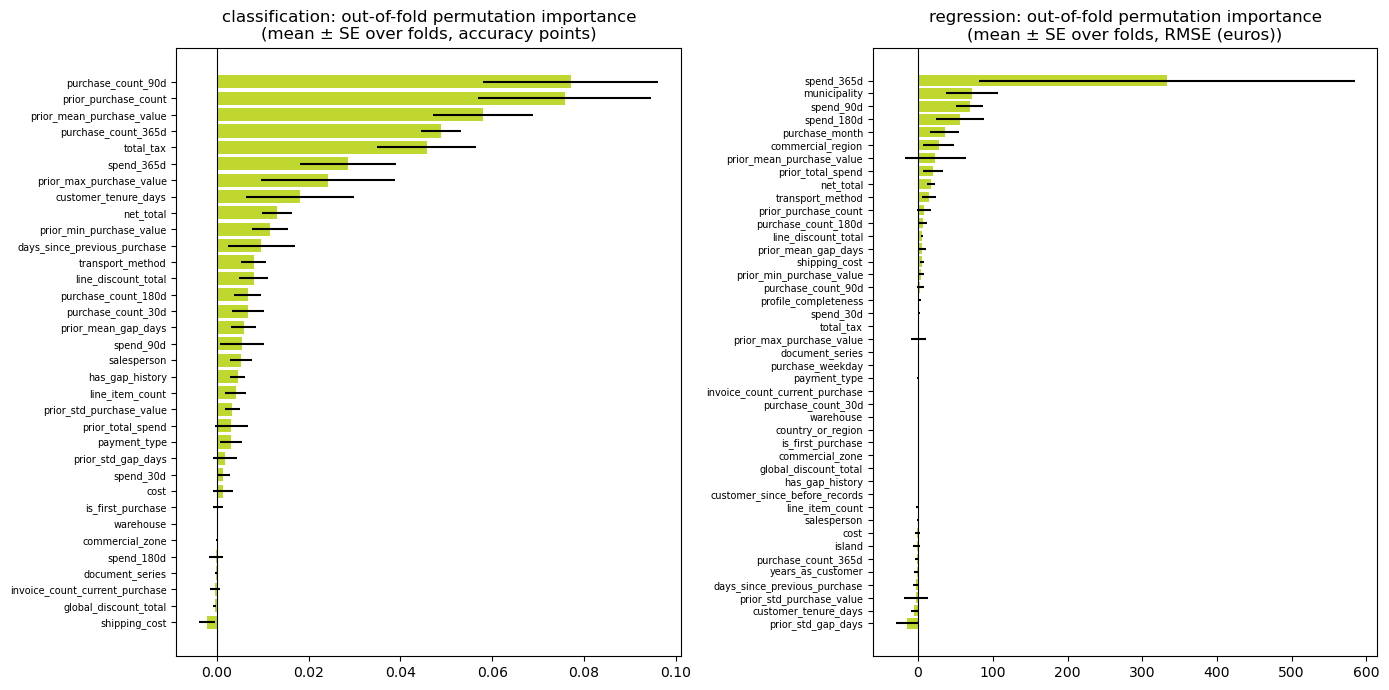

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, task in zip(axes, TASKS):
    p = perm[task].sort_values("mean")
    ax.barh(p.index, p["mean"], xerr=p["std_between_folds"] / np.sqrt(len(folds[task])), color="#BFD72F")
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"{task}: out-of-fold permutation importance\n(mean ± SE over folds, {unit[task]})")
    ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()
plt.show()

## 4. Drop candidates

One row per feature in the recipe, with the evidence side by side. A feature is flagged as a **drop candidate** when it satisfies **both**:

- *not useful*: mean permutation importance `<= 0`, or positive on at most 2 of the folds;
- *and* either *redundant* (it shares a Spearman cluster with another feature in the recipe) or *irrelevant* (MI not above the shuffled-target maximum).

The two-condition rule is deliberately strict: a single weak signal (for example a low importance on its own) is not enough to remove a column, because with 5 folds and a few thousand rows the importance of correlated features is split between them and each looks weaker than it is.

In [9]:
def candidate_table(task):
    g = groups[task]
    used = [c for c in g["used"] if c in perm[task].index]
    sizes = cluster[task].map(cluster[task].value_counts())
    in_recipe_in_cluster = {
        c: [m for m in cluster[task][cluster[task] == cluster[task].get(c)].index if m != c and m in g["used"]]
        for c in used if c in cluster[task].index}
    table = pd.DataFrame(index=used)
    table["VIF"] = vif[task].reindex(used)
    table["MI"] = mi[task].reindex(used)
    table["perm_mean"] = perm[task]["mean"]
    table["perm_folds_positive"] = perm[task]["folds_positive"]
    table["redundant_with"] = pd.Series({c: ", ".join(v) for c, v in in_recipe_in_cluster.items()})
    not_useful = (table["perm_mean"] <= 0) | (table["perm_folds_positive"] <= 2)
    redundant = table["redundant_with"].fillna("") != ""
    irrelevant = table["MI"] <= mi_floor[task].max()
    table["drop_candidate"] = not_useful & (redundant | irrelevant)
    return table.sort_values(["drop_candidate", "perm_mean"], ascending=[False, True])


candidates = {task: candidate_table(task) for task in TASKS}
for task in TASKS:
    t = candidates[task]
    print(f"\n{task.upper()}: {int(t['drop_candidate'].sum())} drop candidates out of {len(t)} features in the recipe")
    display(t.round(4).head(15))


CLASSIFICATION: 8 drop candidates out of 34 features in the recipe


,VIF,MI,perm_mean,perm_folds_positive,redundant_with,drop_candidate
shipping_cost,1.1060,0.0042,-0.0022,1,,True
global_discount_total,1.0144,0.0027,-0.0005,0,,True
invoice_count_current_purchase,1.1156,0.0023,-0.0004,3,,True
document_series,NaN,0.0007,-0.0002,0,NaN,True
spend_180d,10.6634,0.0846,-0.0001,2,spend_365d,True
commercial_zone,NaN,0.0015,-0.0000,2,NaN,True
warehouse,NaN,0.0011,0.0000,0,NaN,True
is_first_purchase,3.0206,0.0110,0.0002,2,,True
cost,3.2667,0.0000,0.0013,3,,False
spend_30d,2.7632,0.0254,0.0014,4,purchase_count_30d,False



REGRESSION: 9 drop candidates out of 43 features in the recipe


,VIF,MI,perm_mean,perm_folds_positive,redundant_with,drop_candidate
prior_std_purchase_value,18.5027,0.2135,-2.5518,3,prior_max_purchase_value,True
cost,3.4450,0.0000,-0.8306,4,,True
line_item_count,2.1347,0.0056,-0.4243,3,,True
customer_since_before_records,1.4037,0.0122,-0.0671,1,,True
has_gap_history,3.7925,0.0182,-0.0100,2,,True
global_discount_total,1.0322,0.0028,-0.0000,1,,True
purchase_count_30d,4.9963,0.0847,0.1512,2,spend_30d,True
purchase_weekday,1.1976,0.0175,0.4619,2,,True
profile_completeness,1.1960,0.0091,1.6448,2,,True
prior_std_gap_days,2.0952,0.1772,-15.2617,1,,False


### 4.1 A first engineering hint: the tax rate

`total_tax` is the 5th most important column for classification (more than `net_total`, which it is almost proportional to). A ratio of the two columns is the tax rate of the invoice; if it takes a handful of fixed values, those values behave like a categorical variable (VAT band, which depends on the product mix or the delivery region) that no current feature exposes directly.

In [10]:
X, y = data["classification"]["X_dev"], data["classification"]["y_dev"]
tax_rate = (X["total_tax"].astype("float64") / X["net_total"].astype("float64")).replace([np.inf, -np.inf], np.nan)
band = tax_rate.round(2).where(tax_rate.round(2).isin(tax_rate.round(2).value_counts().head(4).index), other=np.nan)
by_band = (pd.DataFrame({"band": band.fillna(-1), "repeat_purchase_90d": y})
           .groupby("band")["repeat_purchase_90d"].agg(["size", "mean"]).rename(columns={"size": "rows", "mean": "repurchase_rate"}))
by_band.index = by_band.index.map(lambda v: "other" if v == -1 else f"{v:.2f}")
print(f"distinct tax rates (rounded to 2 decimals): {tax_rate.round(2).nunique()}")
display(by_band.round(3))

distinct tax rates (rounded to 2 decimals): 20


,rows,repurchase_rate
band,,
other,228,0.399
0.00,127,0.386
0.13,191,0.691
0.22,105,0.667
0.23,4373,0.553


## 5. What to do with this

1. **Redundancy and drop candidates** feed the in-pipeline `selection` step (variance threshold, L1 / forest-based selector, top-k) that is added to `build_pipeline`; the same candidates are also tested as a manual ablation (recipe minus the candidate group).
2. **Features worth engineering** are the ones whose information is spread over several correlated columns (the 30/90/180/365-day windows and the `prior_*` statistics): ratios and differences between them (trend, overdue ratio, frequency) are the first engineering candidates.
3. Every decision, kept or rejected, goes to `config.yaml` with a comment pointing to the section of this notebook, and to sections 5 and 12 of the README.

*Caveats: (a) permutation importance depends on the model in `config.yaml`; if the group changes the final model, re-run this notebook. (b) With correlated features, the importance of a group is shared among its members, so the ablation is the arbiter, not this table.*

## 6. Step 2: engineered features, paired ablation

Candidates (computed in `config.yaml` → `diagnostics.derived_features`, only used when listed in the recipe), all known at the moment of the purchase and built from columns of the same row:

- `tax_rate = total_tax / net_total`: VAT band of the invoice (section 4.1);
- `overdue_ratio = days_since_previous_purchase / prior_mean_gap_days`: above 1 means the customer is later than their usual rhythm (NaN, then median, for customers without gap history; `has_gap_history` is already a flag);
- `purchase_rate = prior_purchase_count / (customer_tenure_days + 1)`: purchases per day of tenure.
- `count_share_90d = purchase_count_90d / (purchase_count_365d + 1)`: how much of the year's activity is recent;
- `ticket_vs_usual = net_total / prior_mean_purchase_value`: this invoice against the customer's usual ticket (NaN for first purchases);
- `spend_trend = spend_90d - (spend_180d - spend_90d)`: spend in the last 90 days minus spend in the 90 days before (positive: accelerating);
- `gap_variability = prior_std_gap_days / prior_mean_gap_days`: irregularity of the purchase rhythm (NaN without gap history).

`tax_pct` is a **notebook-only** variant: the same tax rate rounded to whole percent and treated as a *categorical* (target-encoded) variable. A linear model cannot use `tax_rate` well if the relation is not monotonic (section 4.1: 13 % and 22 % high, 23 % medium, 0 % low); if `tax_pct` wins, it becomes a stateless step in `src/cleaning.py`.

Every variant is the task's **current recipe** plus the listed feature(s), scored on the same temporal folds. Positive `mean_advantage` means the variant is better than `current` (RMSE differences are sign-flipped); `decisive` means more than 2 standard errors from zero, the rule used in notebook 01. With about ten variants per task, roughly one pass at 2 SE can happen by chance alone, so a single borderline pass is weak evidence: prefer features that help in at least 4 of 5 folds **and** in both tasks, or that have a reason to help beyond the number.

In [11]:
NEW_FEATURES = ["tax_rate", "overdue_ratio", "purchase_rate", "count_share_90d", "ticket_vs_usual", "spend_trend", "gap_variability"]
BEHAVIOUR = [f for f in NEW_FEATURES if f != "tax_rate"]
missing = [f for task in TASKS for f in NEW_FEATURES if f not in data[task]["X_dev"].columns]
assert not missing, f"{missing} not in X_dev: add them to config.yaml -> diagnostics.derived_features"


def model_factory(task):
    return lambda: get_task(task).model.build_model(config[task]["model"])


def with_extra(recipe, numeric=(), categorical=()):
    return {**recipe, "numeric_features": recipe["numeric_features"] + list(numeric),
            "categorical_features": recipe["categorical_features"] + list(categorical)}


def run_ablation(task, X, variants, baseline="current"):
    """Scores every variant on the task's temporal folds; returns (scores, paired comparison vs baseline)."""
    metric = config[task]["selection_metric"]
    higher = greater_is_better(SCORING[task][metric])
    table, per_fold = compare_preprocessing_variants(
        variants, model_factory(task), X, data[task]["y_dev"], folds[task], SCORING[task], metric)
    paired = pd.DataFrame([{"variant": name, **paired_comparison(per_fold[name], per_fold[baseline], higher)}
                           for name in variants if name != baseline]).set_index("variant")
    return table, paired


def tax_pct(X):
    pct = (X["total_tax"].astype("float64") / X["net_total"].astype("float64") * 100).replace([np.inf, -np.inf], np.nan).round()
    return pct.map(lambda v: f"{int(v)}" if pd.notna(v) else np.nan)


engineering = {}
for task in TASKS:
    X = data[task]["X_dev"].assign(tax_pct=lambda d: tax_pct(d))
    recipe = data[task]["preprocessing_config"]
    variants = {"current": recipe}
    for feature in NEW_FEATURES:
        variants[f"+ {feature}"] = with_extra(recipe, [feature])
    variants["+ tax_pct (categorical)"] = with_extra(recipe, categorical=["tax_pct"])
    variants["+ all behaviour features"] = with_extra(recipe, BEHAVIOUR)
    variants["+ all numeric"] = with_extra(recipe, NEW_FEATURES)
    engineering[task] = run_ablation(task, X, variants)
    metric = config[task]["selection_metric"]
    print(f"\n{task.upper()} ({metric}, {'higher' if greater_is_better(SCORING[task][metric]) else 'lower'} is better)")
    display(engineering[task][0].round(4))
    display(engineering[task][1].round(4))


CLASSIFICATION (accuracy, higher is better)


,variant,mean_accuracy,std_accuracy
0,+ tax_rate,0.7078,0.0168
1,+ ticket_vs_usual,0.7078,0.0190
2,+ spend_trend,0.7078,0.0171
3,+ tax_pct (categorical),0.7076,0.0180
4,current,0.7071,0.0172
5,+ purchase_rate,0.7066,0.0143
6,+ gap_variability,0.7064,0.0166
7,+ overdue_ratio,0.7054,0.0152
8,+ count_share_90d,0.7040,0.0118
9,+ all numeric,0.7038,0.0119


,mean_advantage,se,folds_a_better,n_folds,decisive
variant,,,,,
+ tax_rate,0.0007,0.0013,1,5,False
+ overdue_ratio,-0.0017,0.0024,1,5,False
+ purchase_rate,-0.0005,0.0018,3,5,False
+ count_share_90d,-0.0031,0.0040,2,5,False
+ ticket_vs_usual,0.0007,0.0013,2,5,False
+ spend_trend,0.0007,0.0005,2,5,False
+ gap_variability,-0.0007,0.0012,2,5,False
+ tax_pct (categorical),0.0005,0.0010,2,5,False
+ all behaviour features,-0.0033,0.0034,1,5,False



REGRESSION (rmse, lower is better)


,variant,mean_rmse,std_rmse
0,+ purchase_rate,1938.7625,168.9154
1,current,1943.2316,165.4157
2,+ ticket_vs_usual,1943.9564,165.8162
3,+ tax_pct (categorical),1944.5586,166.0245
4,+ tax_rate,1944.7206,168.2655
5,+ overdue_ratio,1944.8786,165.8784
6,+ spend_trend,1947.3839,167.2814
7,+ count_share_90d,1950.1540,171.2532
8,+ all behaviour features,1979.3268,223.1767
9,+ gap_variability,1979.6077,214.6212


,mean_advantage,se,folds_a_better,n_folds,decisive
variant,,,,,
+ tax_rate,-1.4891,2.1660,2,5,False
+ overdue_ratio,-1.6471,1.2452,1,5,False
+ purchase_rate,4.4690,2.0946,4,5,True
+ count_share_90d,-6.9224,9.5252,3,5,False
+ ticket_vs_usual,-0.7249,1.8549,2,5,False
+ spend_trend,-4.1524,6.9196,3,5,False
+ gap_variability,-36.3761,37.3623,2,5,False
+ tax_pct (categorical),-1.3270,2.9400,2,5,False
+ all behaviour features,-36.0952,40.9257,3,5,False


## 7. Step 3: feature selection, paired ablation

Every selector below sits **inside the Pipeline**, between the recipe and the model (`preprocessing.selection` in `config.yaml`, built by `build_selector` in `src/preprocessing.py`), so it is fitted on the training rows of each fold and never sees the validation rows. All variants start from the task's current recipe, so the comparison isolates the effect of selecting.

- `manual: drop candidates` removes the drop candidates of section 4 from the recipe (they were chosen on all development rows, so this variant is slightly optimistic: it is a reference, not a clean estimate);
- `variance` drops constant columns; `kbest` keeps the k columns with the highest mutual information; `forest` keeps columns whose forest importance is above the mean (or median); `l1` keeps the columns with a non-zero L1 coefficient (logistic regression with strength `C`, Lasso with `alpha`).

Decision rule: add a selector only if it is decisively better, or not decisively worse **and** keeps clearly fewer columns (parsimony). Report either outcome.

In [12]:
def drop_features(recipe, names):
    names = set(names)
    return {**recipe, **{key: [c for c in recipe.get(key, []) if c not in names]
                         for key in ["numeric_features", "categorical_features", "flag_features", "mnar_indicator_sources"]}}


L1_GRID = {"classification": [{"C": 0.01}, {"C": 0.1}, {"C": 1.0}],
           "regression": [{"alpha": 1.0}, {"alpha": 10.0}, {"alpha": 100.0}]}


def selection_variants(task):
    recipe = data[task]["preprocessing_config"]
    manual = candidates[task].index[candidates[task]["drop_candidate"]]
    chosen = lambda **sel: {**recipe, "selection": sel}
    variants = {"current": recipe, "manual: drop candidates": drop_features(recipe, manual),
                "variance": chosen(method="variance"),
                "kbest k=20": chosen(method="kbest", k=20), "kbest k=15": chosen(method="kbest", k=15),
                "forest mean": chosen(method="forest", threshold="mean"),
                "forest median": chosen(method="forest", threshold="median")}
    for params in L1_GRID[task]:
        variants["l1 " + ", ".join(f"{k}={v}" for k, v in params.items())] = chosen(method="l1", **params)
    return variants


def kept_summary(task, variants):
    X, y = data[task]["X_dev"], data[task]["y_dev"]
    rows = []
    for name, recipe in variants.items():
        pipeline = build_pipeline(recipe, model_factory(task)()).fit(X, y)
        width = pipeline.named_steps["prep"].transform(X.iloc[:5]).shape[1]
        kept = list(pipeline[:-1].get_feature_names_out())
        every = list(pipeline.named_steps["prep"].get_feature_names_out())
        rows.append({"variant": name, "columns kept": len(kept), "of": width,
                     "dropped": ", ".join(c.split("__", 1)[-1] for c in every if c not in kept)})
    return pd.DataFrame(rows).set_index("variant")


selection = {}
for task in TASKS:
    variants = selection_variants(task)
    selection[task] = run_ablation(task, data[task]["X_dev"], variants) + (kept_summary(task, variants),)
    metric = config[task]["selection_metric"]
    print(f"\n{task.upper()} ({metric}, {'higher' if greater_is_better(SCORING[task][metric]) else 'lower'} is better)")
    display(selection[task][0].round(4))
    display(selection[task][1].round(4))
    with pd.option_context("display.max_colwidth", 140):
        display(selection[task][2])


CLASSIFICATION (accuracy, higher is better)


,variant,mean_accuracy,std_accuracy
0,manual: drop candidates,0.7100,0.0157
1,l1 C=1.0,0.7085,0.0201
2,kbest k=20,0.7074,0.0209
3,l1 C=0.1,0.7074,0.0209
4,current,0.7071,0.0172
5,variance,0.7071,0.0172
6,forest mean,0.7050,0.0198
7,forest median,0.7045,0.0185
8,kbest k=15,0.7042,0.0200
9,l1 C=0.01,0.6992,0.0150


,mean_advantage,se,folds_a_better,n_folds,decisive
variant,,,,,
manual: drop candidates,0.0029,0.0019,4,5,False
variance,0.0000,0.0000,0,5,False
kbest k=20,0.0002,0.0058,3,5,False
kbest k=15,-0.0029,0.0046,1,5,False
forest mean,-0.0022,0.0044,1,5,False
forest median,-0.0026,0.0037,1,5,False
l1 C=0.01,-0.0079,0.0072,1,5,False
l1 C=0.1,0.0002,0.0035,2,5,False
l1 C=1.0,0.0014,0.0020,3,5,False


,columns kept,of,dropped
variant,,,
current,35,35,
manual: drop candidates,27,27,
variance,35,35,
kbest k=20,20,35,"net_total, total_tax, shipping_cost, global_discount_total, line_discount_total, cost, line_item_count, invoice_count_current_purchase, ..."
kbest k=15,15,35,"net_total, total_tax, shipping_cost, global_discount_total, line_discount_total, cost, line_item_count, invoice_count_current_purchase, ..."
forest mean,18,35,"shipping_cost, global_discount_total, line_item_count, invoice_count_current_purchase, customer_tenure_days, prior_purchase_count, prior..."
forest median,18,35,"shipping_cost, global_discount_total, line_item_count, invoice_count_current_purchase, customer_tenure_days, prior_purchase_count, prior..."
l1 C=0.01,8,35,"net_total, shipping_cost, global_discount_total, line_discount_total, cost, line_item_count, invoice_count_current_purchase, customer_te..."
l1 C=0.1,19,35,"cost, invoice_count_current_purchase, days_since_previous_purchase, prior_total_spend, prior_mean_purchase_value, prior_std_purchase_val..."



REGRESSION (rmse, lower is better)


,variant,mean_rmse,std_rmse
0,current,1943.2316,165.4157
1,variance,1943.2316,165.4157
2,l1 alpha=1.0,1945.0070,174.2330
3,manual: drop candidates,1946.2310,142.2657
4,forest median,1951.0598,171.6038
5,forest mean,1961.6574,172.3083
6,l1 alpha=10.0,1962.8969,182.0946
7,kbest k=15,1994.5719,181.9640
8,kbest k=20,2015.0424,194.7946
9,l1 alpha=100.0,2147.7620,202.1176


,mean_advantage,se,folds_a_better,n_folds,decisive
variant,,,,,
manual: drop candidates,-2.9994,13.5175,2,5,False
variance,-0.0000,0.0000,1,5,False
kbest k=20,-71.8108,23.4155,0,5,True
kbest k=15,-51.3403,23.8080,1,5,True
forest mean,-18.4258,5.4254,0,5,True
forest median,-7.8282,4.1402,2,5,False
l1 alpha=1.0,-1.7754,17.0604,4,5,False
l1 alpha=10.0,-19.6653,24.1514,2,5,False
l1 alpha=100.0,-204.5304,56.4491,0,5,True


,columns kept,of,dropped
variant,,,
current,44,44,
manual: drop candidates,35,35,
variance,44,44,
kbest k=20,20,44,"net_total, total_tax, shipping_cost, global_discount_total, line_discount_total, cost, line_item_count, invoice_count_current_purchase, ..."
kbest k=15,15,44,"net_total, total_tax, shipping_cost, global_discount_total, line_discount_total, cost, line_item_count, invoice_count_current_purchase, ..."
forest mean,9,44,"net_total, total_tax, shipping_cost, global_discount_total, line_discount_total, cost, line_item_count, invoice_count_current_purchase, ..."
forest median,22,44,"total_tax, shipping_cost, global_discount_total, line_discount_total, invoice_count_current_purchase, days_since_previous_purchase, purc..."
l1 alpha=1.0,37,44,"total_tax, global_discount_total, prior_min_purchase_value, prior_max_purchase_value, prior_std_gap_days, purchase_count_90d, has_gap_hi..."
l1 alpha=10.0,21,44,"net_total, total_tax, shipping_cost, global_discount_total, line_discount_total, cost, line_item_count, invoice_count_current_purchase, ..."


## 8. Decisions

**Scope.** All numbers come from sections 4, 6 and 7 of this notebook (five temporal folds, development set only; classification scored with logistic regression and accuracy, regression with a random forest and RMSE). The final report will use probably other models, so the decisions below are about columns, not models, and rest as far as possible on evidence that does not depend on a single model: mutual information against a shuffled-target noise floor, exact duplicates and correlation. Permutation importance is only supporting evidence: near zero it is noisy, and the number of regression drop candidates went from 11 to 9 between two runs after columns were added to the data.

**Features to create.** Of the seven engineered features, only `purchase_rate` (`prior_purchase_count / (customer_tenure_days + 1)`) helps, and only in regression: RMSE improves by 4.5 (about 0.2 %), in 4 of 5 folds, at 2.1 standard errors. With about ten comparisons per task this is borderline, so it is kept as an optional feature with a small expected gain, not as a finding. Its mutual information with the target is among the highest in both tasks (4th in classification, 3rd in regression), which suggests it may matter more for models that cannot form ratios by themselves. `tax_rate`, `tax_pct`, `overdue_ratio`, `count_share_90d`, `ticket_vs_usual` and `spend_trend` change nothing (no difference is decisive and most are slightly negative), and `gap_variability` makes regression worse and less stable (RMSE +36, standard deviation across folds from 165 to 215). None of them is created.

**Columns to delete.** Columns without signal (mutual information below the noise floor, zero or negligible permutation importance): in both tasks `global_discount_total`, `document_series` and `commercial_zone`; in classification also `shipping_cost`, `warehouse`, `invoice_count_current_purchase` and `is_first_purchase` (identical to `prior_purchase_count == 0`); in regression also `cost`, `line_item_count`, `customer_since_before_records`, `has_gap_history` (identical to `prior_purchase_count >= 2`), `purchase_weekday` and `profile_completeness`. Removing the drop candidates of section 4 by hand did not hurt: accuracy +0.0029 with 27 instead of 35 model columns, RMSE −3.0 (not decisive) with 35 instead of 44. Both numbers are optimistic, because the candidates were chosen on the same rows, and the final lists above differ slightly from the tested ones, so they still need one confirming ablation.

**Redundant but informative.** `spend_180d` (classification), `prior_std_purchase_value` and `purchase_count_30d` (regression) and `purchase_count_180d` (VIF 29) duplicate information held by other columns. Tree-based models tolerate this, so they are removed only if a linear or distance-based model is among the final five.

**Feature-selection step.** No automatic selector beats the manual list. `kbest` and forest-mean selection are decisively worse in regression, and L1 logistic regression (`C=0.1`) matches the full recipe in classification with 19 of 35 columns, but that result depends on the model. The `selection` step stays in the pipeline with `method: none` as the default and can be re-tested once the five models are fixed.

**Limits.** The evidence comes from logistic regression and a random forest only. Sections 6 and 7 should be re-run for each of the final models before the lists are frozen.